# PREDICCIÓN DE LA PRIMA: REGRESIÓN LINEAL MÚLTIPLE VS POLINÓMICA

Queremos predecir la prima del seguro incluyendo la probabilidad de impago como variable. Comparamos una regresión lineal múltiple con una polinómica para ver cuál predice mejor.

## IMPORTAR LIBRERÍAS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, cross_val_score, learning_curve
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## CARGA DE LOS DATOS

In [2]:
base_path = Path.cwd()
prestamos = pd.read_csv(base_path / "datos" / "prestamos_con_prob.csv")
prestamos.head()

,Unnamed: 0,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,...,Estudios_Grado Universitario,Estudios_Máster,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero,Prob_Impago
0,0,O77MPJ,26,19153,6973,706,9,1,19.05,36,...,True,False,False,False,True,False,False,False,True,0.371503
1,8,IYOL1S,29,39531,40000,826,0,1,9.74,24,...,False,False,False,False,True,False,True,False,False,0.143517
2,9,FRMZVN,29,40348,16448,740,9,1,14.73,24,...,False,True,False,False,True,False,False,False,True,0.243430
3,26,YKHXVY,38,41732,42040,661,173,2,13.24,48,...,True,False,False,False,False,True,True,False,False,0.147482
4,32,NHDJTK,35,35085,16406,759,181,1,9.74,36,...,False,False,False,False,True,False,True,False,False,0.105655


## ANÁLISIS DESCRIPTIVO

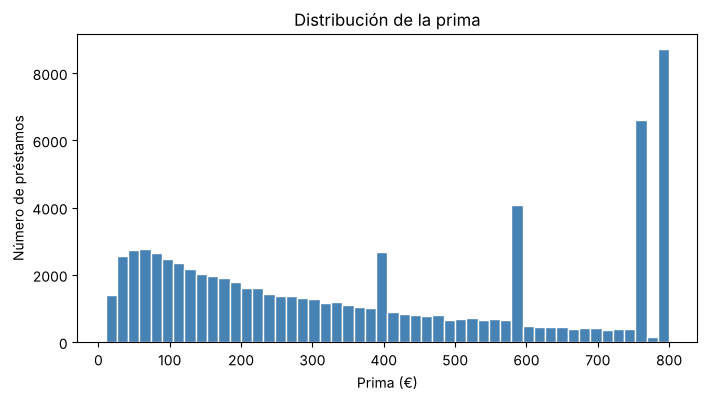

count    76924.000000
mean       383.694225
std        267.385642
min         10.000000
25%        137.130000
50%        332.670000
75%        610.615000
max        800.000000
Name: Prima, dtype: float64


In [3]:
plt.figure(figsize=(8, 4))
plt.hist(prestamos["Prima"], bins=50, color="steelblue", edgecolor="white")
plt.xlabel("Prima (€)")
plt.ylabel("Número de préstamos")
plt.title("Distribución de la prima")
plt.show()

print(prestamos["Prima"].describe())

La prima media es de unos 384 € y va de 10 € a 800 €. Hay muchos préstamos justo en 800 €, que parece ser el máximo.

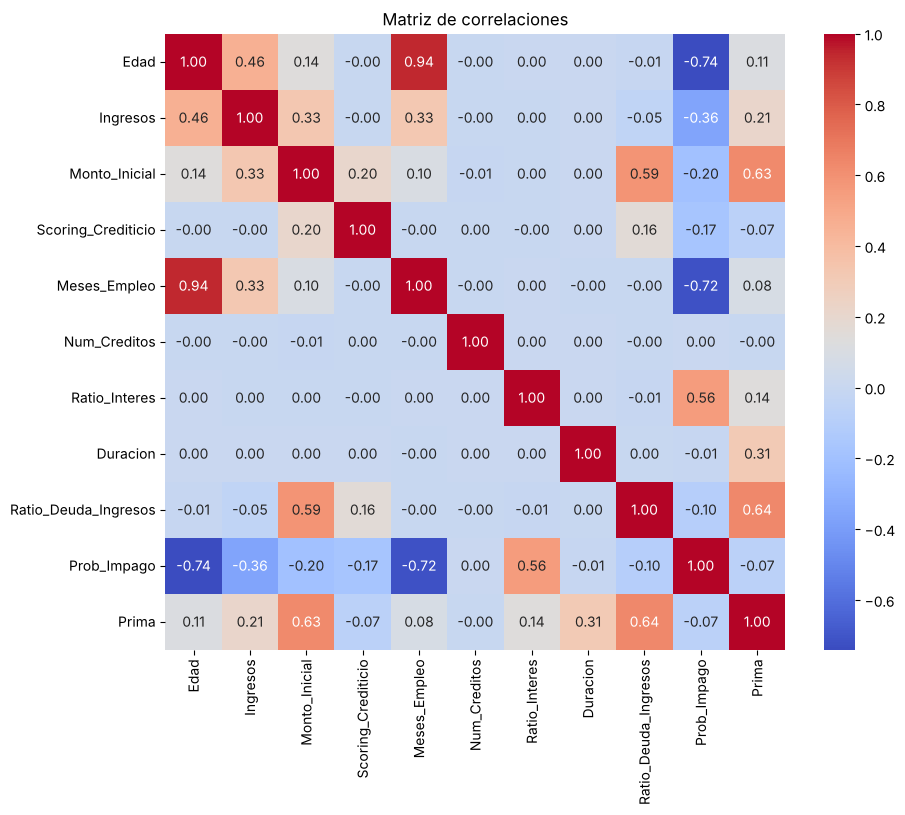

Scoring_Crediticio     -0.072778
Prob_Impago            -0.068986
Num_Creditos           -0.004290
Meses_Empleo            0.083582
Edad                    0.113294
Ratio_Interes           0.137107
Ingresos                0.212776
Duracion                0.312989
Monto_Inicial           0.627024
Ratio_Deuda_Ingresos    0.635548
Prima                   1.000000
Name: Prima, dtype: float64


In [4]:
corr = prestamos[["Edad", "Ingresos", "Monto_Inicial", "Scoring_Crediticio", "Meses_Empleo",
                  "Num_Creditos", "Ratio_Interes", "Duracion", "Ratio_Deuda_Ingresos",
                  "Prob_Impago", "Prima"]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de correlaciones")
plt.show()

print(corr["Prima"].sort_values())

Las variables más relacionadas con la prima son el ratio deuda ingresos, el importe y la duración. La probabilidad de impago casi no se relaciona con la prima.

In [5]:
tramos = pd.cut(prestamos["Monto_Inicial"], [0, 5000, 10000, 20000, 40000, 60000, 100000, 400000])
prestamos.groupby(tramos, observed=True)["Prima"].agg(["mean", "count"]).round(1)

,mean,count
Monto_Inicial,,
"(0, 5000]",43.6,4320
"(5000, 10000]",87.0,7739
"(10000, 20000]",157.6,13156
"(20000, 40000]",422.4,29821
"(40000, 60000]",539.7,6783
"(60000, 100000]",664.3,7317
"(100000, 400000]",701.2,7788


Cuanto mayor es el préstamo, más alta es la prima, pero no sube siempre igual. La relación es curva, por eso probamos también la polinómica.

## SEPARAR EN X E Y

Quitamos la prima porque es lo que queremos predecir, los identificadores, el impago porque se conoce después, y una categoría de cada grupo de dummies para evitar multicolinealidad.

In [6]:
X = prestamos.drop(columns=['Prima', 'Impago', 'Unnamed: 0', 'ID',
                            'Estudios_Escolar', 'Tipo_Jornada_Laboral_Jornada completa',
                            'Estado_Civil_Casado'])
y = prestamos['Prima']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    train_size=0.8,
                                                    random_state=42,
                                                    shuffle=True)

print("Variables explicativas:", X.shape[1])
print("Observaciones train:", X_train.shape[0], "| test:", X_test.shape[0])

Variables explicativas: 21
Observaciones train: 61539 | test: 15385


## ESCALAR

Escalamos las variables para que todas tengan el mismo peso. En la polinómica es aún más importante porque al elevar al cubo salen números muy grandes.

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 1. REGRESIÓN LINEAL MÚLTIPLE

In [8]:
modelo_lineal = LinearRegression().fit(X_train_scaled, y_train)

print("Intercepto:", round(modelo_lineal.intercept_, 2))
coeficientes = pd.Series(modelo_lineal.coef_, index=X.columns).sort_values()
print(coeficientes.round(2))

Intercepto: 383.9
Scoring_Crediticio                     -64.08
Prob_Impago                            -35.97
Edad                                   -14.28
Meses_Empleo                            -0.76
Num_Creditos                            -0.64
Fiador                                  -0.36
Posesion_Hipoteca                       -0.32
Personas_Cargo                          -0.11
Tipo_Jornada_Laboral_Desempleado        -0.02
Tipo_Jornada_Laboral_Tiempo parcial      0.30
Tipo_Jornada_Laboral_Autónomo            0.39
Estado_Civil_Soltero                     0.42
Estado_Civil_Divorciado                  0.67
Estudios_Grado Universitario             7.94
Estudios_Doctorado                       7.98
Estudios_Máster                         11.46
Ingresos                                17.72
Ratio_Interes                           57.06
Duracion                                82.83
Monto_Inicial                           95.29
Ratio_Deuda_Ingresos                   122.69
dtype: float64


Las variables que más suben la prima son el ratio deuda ingresos, el importe y la duración. El scoring y la probabilidad de impago la bajan un poco.

### Métricas

In [9]:
pred_train_lineal = modelo_lineal.predict(X_train_scaled)
pred_test_lineal = modelo_lineal.predict(X_test_scaled)

n = X_train_scaled.shape[0]
p = X_train_scaled.shape[1]
r2_train_lineal = r2_score(y_train, pred_train_lineal)
r2_ajustado_lineal = 1 - (1 - r2_train_lineal) * (n - 1) / (n - p - 1)

print("R² train:", round(r2_train_lineal, 3))
print("R² ajustado:", round(r2_ajustado_lineal, 3))
print("R² test:", round(r2_score(y_test, pred_test_lineal), 3))
print("RMSE test:", round(mean_squared_error(y_test, pred_test_lineal) ** 0.5, 2), "€")
print("MAE test:", round(mean_absolute_error(y_test, pred_test_lineal), 2), "€")

R² train: 0.681
R² ajustado: 0.681
R² test: 0.679
RMSE test: 151.77 €
MAE test: 119.67 €


- El modelo explica un 68 % de la prima.
- Se equivoca de media en unos 120 €, bastante para una prima media de 384 €.
- Train y test dan casi lo mismo, así que no sobreajusta, pero se queda corto porque los datos son curvos.

# 2. REGRESIÓN POLINÓMICA

### Elegir el grado

Probamos grados 1, 2 y 3 con validación cruzada de 5 partes y nos quedamos con el que menos error tenga. No probamos grado 4 porque saldrían demasiadas variables.

In [10]:
clase_poly_grado_1 = PolynomialFeatures(degree=1, include_bias=False)
X_train_grado_1 = clase_poly_grado_1.fit_transform(X_train_scaled)

scores_grado_1 = cross_val_score(LinearRegression(), X_train_grado_1, y_train, cv=5,
                                 scoring="neg_root_mean_squared_error")

print("Grado 1 | variables:", X_train_grado_1.shape[1])
print("RMSE medio:", round(-scores_grado_1.mean(), 2), "€ | desviación:", round(scores_grado_1.std(), 2))

Grado 1 | variables: 21
RMSE medio: 151.02 € | desviación: 0.5


In [11]:
clase_poly_grado_2 = PolynomialFeatures(degree=2, include_bias=False)
X_train_grado_2 = clase_poly_grado_2.fit_transform(X_train_scaled)

scores_grado_2 = cross_val_score(LinearRegression(), X_train_grado_2, y_train, cv=5,
                                 scoring="neg_root_mean_squared_error")

print("Grado 2 | variables:", X_train_grado_2.shape[1])
print("RMSE medio:", round(-scores_grado_2.mean(), 2), "€ | desviación:", round(scores_grado_2.std(), 2))

Grado 2 | variables: 252
RMSE medio: 97.05 € | desviación: 0.34


In [12]:
clase_poly_grado_3 = PolynomialFeatures(degree=3, include_bias=False)
X_train_grado_3 = clase_poly_grado_3.fit_transform(X_train_scaled)

scores_grado_3 = cross_val_score(LinearRegression(), X_train_grado_3, y_train, cv=5,
                                 scoring="neg_root_mean_squared_error")

print("Grado 3 | variables:", X_train_grado_3.shape[1])
print("RMSE medio:", round(-scores_grado_3.mean(), 2), "€ | desviación:", round(scores_grado_3.std(), 2))

Grado 3 | variables: 2023
RMSE medio: 75.7 € | desviación: 0.3


El error baja mucho al subir el grado: 151 € con grado 1, 97 € con grado 2 y 76 € con grado 3. La desviación es muy pequeña, así que el resultado es estable. Elegimos grado 3.

### Modelo de grado 3

In [13]:
X_test_grado_3 = clase_poly_grado_3.transform(X_test_scaled)

modelo_polinomico_grado_3 = LinearRegression().fit(X_train_grado_3, y_train)

### Métricas

In [14]:
pred_train_grado_3 = modelo_polinomico_grado_3.predict(X_train_grado_3)
pred_test_grado_3 = modelo_polinomico_grado_3.predict(X_test_grado_3)

p_grado_3 = X_train_grado_3.shape[1]
r2_train_grado_3 = r2_score(y_train, pred_train_grado_3)
r2_ajustado_grado_3 = 1 - (1 - r2_train_grado_3) * (n - 1) / (n - p_grado_3 - 1)

print("R² train:", round(r2_train_grado_3, 3))
print("R² ajustado:", round(r2_ajustado_grado_3, 3))
print("R² test:", round(r2_score(y_test, pred_test_grado_3), 3))
print("RMSE test:", round(mean_squared_error(y_test, pred_test_grado_3) ** 0.5, 2), "€")
print("MAE test:", round(mean_absolute_error(y_test, pred_test_grado_3), 2), "€")

R² train: 0.926
R² ajustado: 0.923
R² test: 0.921
RMSE test: 75.27 €
MAE test: 56.12 €


- El modelo explica un 92 % de la prima.
- Se equivoca de media en unos 56 €, menos de la mitad que el lineal.
- Train y test dan casi igual, así que no sobreajusta aunque tenga muchas variables.

### Curva de aprendizaje

Vemos cómo cambia el error en train y en validación al ir metiendo más préstamos, para saber si el modelo sobreajusta.

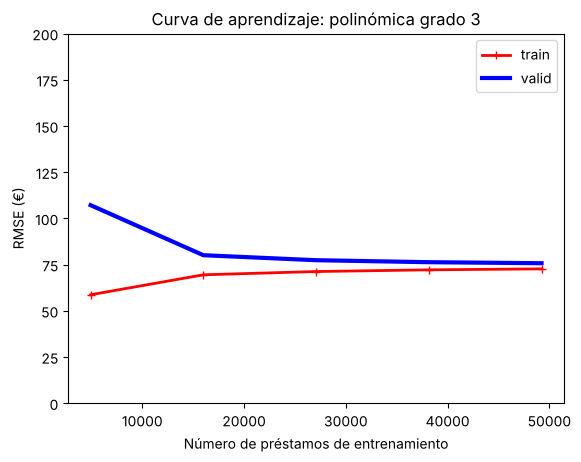

RMSE train: [58.63 69.44 71.2  72.12 72.64]
RMSE valid: [107.11  80.04  77.32  76.25  75.7 ]


In [15]:
train_sizes, train_scores, valid_scores = learning_curve(LinearRegression(), X_train_grado_3, y_train,
                                                         train_sizes=np.linspace(0.1, 1.0, 5),
                                                         cv=5, scoring="neg_root_mean_squared_error")

train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)

plt.plot(train_sizes, train_errors, "r-+", linewidth=2, label="train")
plt.plot(train_sizes, valid_errors, "b-", linewidth=3, label="valid")
plt.ylim(0, 200)
plt.legend()
plt.xlabel("Número de préstamos de entrenamiento")
plt.ylabel("RMSE (€)")
plt.title("Curva de aprendizaje: polinómica grado 3")
plt.show()

print("RMSE train:", np.round(train_errors, 2))
print("RMSE valid:", np.round(valid_errors, 2))

Con pocos datos hay separación entre train y validación, el modelo sobreajusta un poco. Al meter más préstamos las dos curvas se juntan en torno a 73 y 76 €, así que con todos los datos el modelo generaliza bien.

# 3. COMPARACIÓN DE LOS DOS MODELOS

In [16]:
resultados = pd.DataFrame({
    "Modelo": ["Lineal múltiple", "Polinómica grado 3"],
    "Variables": [p, p_grado_3],
    "R² train": [r2_train_lineal, r2_train_grado_3],
    "R² ajustado": [r2_ajustado_lineal, r2_ajustado_grado_3],
    "R² test": [r2_score(y_test, pred_test_lineal), r2_score(y_test, pred_test_grado_3)],
    "RMSE test (€)": [mean_squared_error(y_test, pred_test_lineal) ** 0.5,
                      mean_squared_error(y_test, pred_test_grado_3) ** 0.5],
    "MAE test (€)": [mean_absolute_error(y_test, pred_test_lineal),
                     mean_absolute_error(y_test, pred_test_grado_3)]
}).round(3)

resultados

,Modelo,Variables,R² train,R² ajustado,R² test,RMSE test (€),MAE test (€)
0,Lineal múltiple,21,0.681,0.681,0.679,151.772,119.671
1,Polinómica grado 3,2023,0.926,0.923,0.921,75.273,56.118


## CONCLUSIÓN

- La polinómica de grado 3 es mejor en todas las métricas: explica el 92 % frente al 68 % y el error medio baja de 120 € a 56 €.
- La lineal múltiple es más sencilla y fácil de interpretar, pero no recoge la forma curva de los datos.
- La polinómica tiene muchas más variables, pero como tenemos muchos préstamos no sobreajusta.
- La probabilidad de impago aporta poco a la prima, las variables importantes son el importe, el endeudamiento y la duración.

Por eso elegimos la regresión polinómica de grado 3 para predecir la prima.